<a href="https://colab.research.google.com/github/dzamaadam-afk/analyzy/blob/main/Fourier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

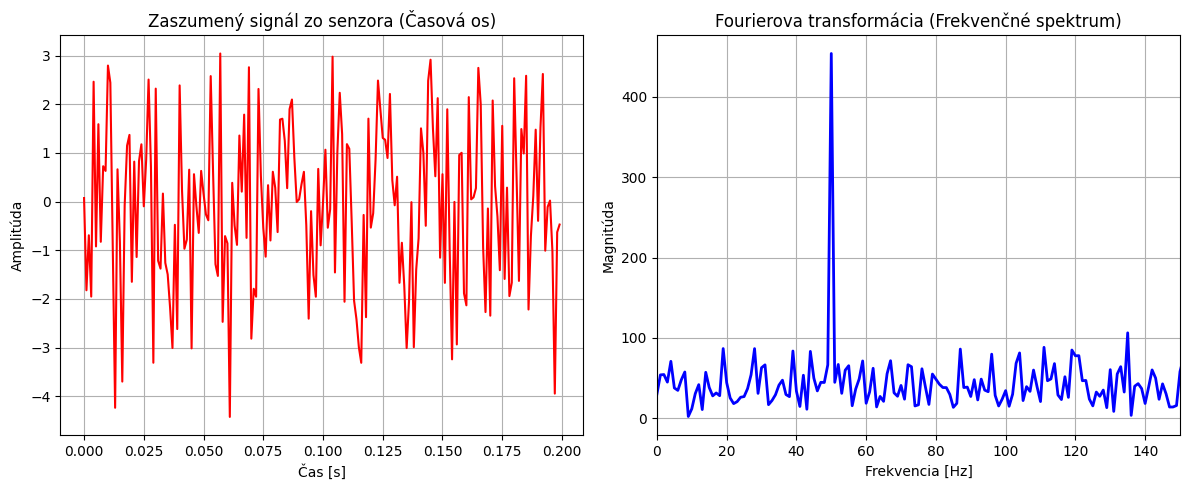

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. DEFINÍCIA FYZIKÁLNYCH PARAMETROV (Vaša matematika)
frekvencia_poruchy = 50.0  # Porucha ložiska kmitá na 50 Hz
frekvencia_vzvorkovania = 1000.0  # Ako rýchlo senzor meria (1000 Hz)
trvanie = 1.0  # Meriame 1 sekundu
t = np.arange(0, trvanie, 1.0 / frekvencia_vzvorkovania)

# 2. GENEROVANIE SIGNÁLU (Čistá sínusoida + štatistický Gaussov šum)
cisty_signal = np.sin(2 * np.pi * frekvencia_poruchy * t)
sum = np.random.normal(0, 1.5, len(t))  # Gaussovo rozdelenie (stredná hodnota=0, odchýlka=1.5)
merany_signal = cisty_signal + sum

# 3. FOURIEROVA TRANSFORMÁCIA (FFT - Prechod z času do frekvencie)
fft_vysledok = np.fft.fft(merany_signal)
frekvencie = np.fft.fftfreq(len(t), 1.0 / frekvencia_vzvorkovania)

# Berieme len kladné frekvencie
amplituda = np.abs(fft_vysledok)[:len(t)//2]
vsetky_frekvencie = frekvencie[:len(t)//2]

# 4. VYKRESLENIE GRAFOV PRE INŽINIERA
plt.figure(figsize=(12, 5))

# Graf 1: Časová os (V tom šume poruchu okom neuvidíte)
plt.subplot(1, 2, 1)
plt.plot(t[:200], merany_signal[:200], color='red')
plt.title("Zaszumený signál zo senzora (Časová os)")
plt.xlabel("Čas [s]")
plt.ylabel("Amplitúda")
plt.grid(True)

# Graf 2: Frekvenčný spektrum (Fourier odhalí presne 50 Hz!)
plt.subplot(1, 2, 2)
plt.plot(vsetky_frekvencie, amplituda, color='blue', linewidth=2)
plt.title("Fourierova transformácia (Frekvenčné spektrum)")
plt.xlabel("Frekvencia [Hz]")
plt.ylabel("Magnitúda")
plt.xlim(0, 150)
plt.grid(True)

plt.tight_layout()
plt.show()